# Активационные функции, оптимизаторы, backpropagation

**Курс «Основы. Специалист по искусственному интеллекту» · Модуль 4. Глубокое обучение**

В предыдущем файле мы рассматривали строение перцептрона и многослойной сети. Теперь откроем процесс обучения: что происходит с сигналом внутри нейрона, как ошибка связывается с параметрами и кто именно меняет веса.

Материал содержит выполненные примеры для занятия и самостоятельного чтения. **Заданий нет.** Перед каждым блоком кода дано введение, после него разобраны используемые конструкции Python, методы и результаты. Формулы, выводы производных и повторение математической теории не используются: механизмы прослеживаются по числам и действиям программы.

Все данные маленькие и создаются внутри файла. Примеры выполняются на CPU без загрузки моделей или датасетов. Используем PyTorch как инструмент, который позволяет отдельно увидеть вычисление ответа, получение градиентов и обновление параметров. Полный обзор нейросетевых фреймворков будет в своей теме.

### Как читать и выполнять материал

Сохранённые выводы можно изучать без запуска Python. Для повторного выполнения выберите **Restart Kernel and Run All / «Перезапустить ядро и выполнить все ячейки»**. Ядро — процесс Python, в котором живут переменные. Ячейки связаны и выполняются сверху вниз.

Обучение меняет состояние параметров и оптимизаторов. Для повторения опыта с исходного состояния нужно заново выполнить его создание, а для повторения всего файла — перезапустить ядро. Отдельные вызовы `backward` также связаны с вычислениями, сделанными перед ними.

Понадобятся Python, PyTorch, NumPy, Pandas, Matplotlib, scikit-learn и среда Jupyter. Установка пакетов из ноутбука не производится. Проверенные версии выводятся ниже. Строение слоёв, предобработка, метрики и схема валидации уже изучались: здесь они нужны для демонстрации обучения, без повторного разбора их теории. Регуляризация, Dropout и Batch Normalization относятся к следующей теме.

Подключим библиотеки и выберем CPU для создаваемых тензоров. Тензор — контейнер чисел PyTorch, который при необходимости участвует в автоматическом вычислении градиентов. Для маленьких примеров ограничимся одним вычислительным потоком и выведем версии среды.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import torch

from torch import nn
from IPython.display import display
from sklearn.datasets import make_moons
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

torch.set_default_device('cpu')
torch.set_num_threads(1)
pd.set_option('display.max_columns', 12)
pd.set_option('display.precision', 4)
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110

print('Python:', sys.version.split()[0])
print('PyTorch:', torch.__version__)
print('NumPy:', np.__version__)
print('Pandas:', pd.__version__)
print('Matplotlib:', matplotlib.__version__)
print('scikit-learn:', sklearn.__version__)
print('Устройство примеров:', torch.get_default_device())

Python: 3.13.13
PyTorch: 2.11.0+xpu
NumPy: 2.4.6
Pandas: 2.3.3
Matplotlib: 3.10.9
scikit-learn: 1.8.0
Устройство примеров: cpu


**Разбор кода.**

- `import` подключает пакет или модуль. `as np`, `as pd`, `as plt` дают короткие имена; точка в `matplotlib.pyplot` указывает вложенный модуль. `from ... import ...` подключает отдельные инструменты. `nn` — модуль PyTorch с готовыми слоями и функциями потерь.
- NumPy нужен для массивов, Pandas — для таблиц, Matplotlib — для рисунков, scikit-learn — для учебных данных и проверки. `display` выводит таблицы внутри ноутбука. Импорт не запускает обучение.
- `torch.set_default_device('cpu')` задаёт CPU для создания тензоров по умолчанию, `set_num_threads(1)` ограничивает вычисления одним потоком в текущем процессе. `get_default_device()` читает выбранное устройство. Текст в кавычках — строка, `1` — целое число.
- `pd.set_option(...)` настраивает вид таблиц, а не точность хранимых данных. `plt.rcParams` хранит настройки рисунков; квадратные скобки выбирают значение по ключу, `=` присваивает новое значение. DejaVu Sans поддерживает кириллицу, `figure.dpi` задаёт плотность изображения.
- `print(...)` выводит текст и значения. `sys.version.split()[0]` разбивает строку сведений о Python по пробелам и берёт первый фрагмент. Позиции в Python считаются с нуля. `.__version__` — атрибут версии пакета.
- Точка выбирает атрибут или метод объекта, круглые скобки вызывают функцию или метод. Конкретные инструменты из импортов поясняются при использовании.

## 1. Активация: преобразование сигнала

Активационная функция получает числовой сигнал нейрона после учёта его входов и выдаёт результат для следующего этапа. Здесь рассмотрим её отдельно: подадим готовые числа, чтобы увидеть именно преобразование.

| Функция | Как изменяет сигнал | Где полезно понимать её поведение |
|---|---|---|
| Sigmoid | Сжимает значения в диапазон от 0 до 1 | При представлении оценки бинарного класса; вдали от середины меняется слабо |
| Tanh | Сжимает значения в диапазон от −1 до 1 | В скрытом слое даёт и отрицательные, и положительные результаты; на краях также меняется слабо |
| ReLU | Отрицательные входы превращает в 0, положительные сохраняет | В скрытых слоях; на отрицательном участке отсутствует чувствительность к входу |
| LeakyReLU | Сохраняет небольшой отрицательный отклик вместо обнуления | Помогает понять отличие от нулевого отклика ReLU |

При конечных входах sigmoid не достигает границ своего диапазона математически, но вычислительное округление может показать 0 или 1. Для tanh также важно различать предельное поведение и отображение чисел. Выбор активации влияет на представление сигнала и на прохождение градиентов при обучении; универсально лучшей функции для всех задач нет.

Передадим одинаковые пять значений четырём активациям. Для LeakyReLU выберем коэффициент отрицательного участка 0,1. Посмотрим результаты рядом; эти числа — входы отдельной функции, а не классы объектов и не веса уже обученной сети.

In [2]:
activation_inputs = torch.tensor([-6.0, -2.0, 0.0, 2.0, 6.0])
leaky_relu = nn.LeakyReLU(negative_slope=0.1)
activation_functions = {
    'Sigmoid': torch.sigmoid,
    'Tanh': torch.tanh,
    'ReLU': torch.relu,
    'LeakyReLU': leaky_relu,
}
activation_table = pd.DataFrame({'Вход': activation_inputs.numpy()})
for name, activation_function in activation_functions.items():
    activation_table[name] = activation_function(activation_inputs).numpy()
display(activation_table)

,Вход,Sigmoid,Tanh,ReLU,LeakyReLU
0,-6.0,0.0025,-1.000,0.0,-0.6
1,-2.0,0.1192,-0.964,0.0,-0.2
2,0.0,0.5000,0.000,0.0,0.0
3,2.0,0.8808,0.964,2.0,2.0
4,6.0,0.9975,1.000,6.0,6.0


**Разбор кода и результата.**

- `torch.tensor([...])` создаёт тензор из списка. Десятичная точка, например в `-6.0`, обозначает число с дробной частью. Здесь хранится одномерная последовательность из пяти чисел без запроса на вычисление градиентов.
- `nn.LeakyReLU(negative_slope=0.1)` создаёт готовое преобразование; параметр сохраняет десятую часть отрицательного входа. Именованный аргумент записывается как `имя=значение` внутри вызова.
- `activation_functions` — словарь. Ключ слева от двоеточия задаёт имя, значение справа — функцию или вызываемый объект. `torch.sigmoid`, `torch.tanh`, `torch.relu` записаны **без скобок**, поэтому сохраняются как инструменты, а не вычисляются в момент создания словаря.
- `.items()` выдаёт пары «имя, инструмент». Цикл `for name, activation_function in ...:` распаковывает пару и выполняет строки с отступом. `activation_function(...)` вызывает текущую функцию или объект на одинаковых входах. Двоеточие и отступ определяют блок цикла.
- `.numpy()` переводит тензор CPU в представление NumPy для таблицы. `pd.DataFrame(...)` создаёт таблицу; `activation_table[name] = ...` добавляет очередной столбец. `display(...)` показывает её.

У ReLU оба отрицательных значения стали нулями, у LeakyReLU остались −0,6 и −0,2. Sigmoid и tanh сжали крупные по величине входы к краям своих диапазонов. Значение tanh или LeakyReLU может быть отрицательным, поэтому результаты этих функций не следует автоматически читать как вероятности классов.

Построим линии преобразований на общей последовательности входов. Ограниченные по диапазону sigmoid и tanh покажем слева, ReLU и LeakyReLU — справа. Разделение панелей позволяет увидеть форму каждой линии без сильного сжатия вертикального масштаба.

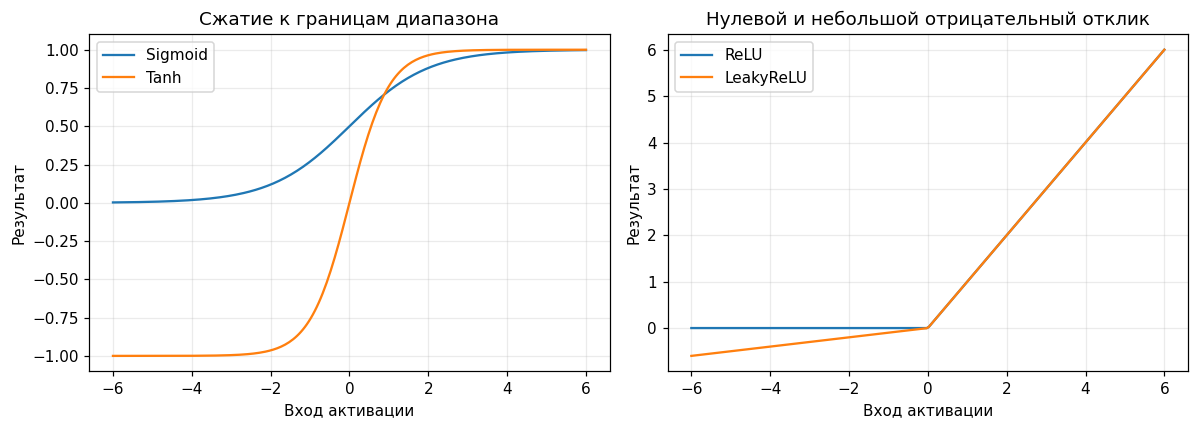

In [3]:
activation_grid = torch.linspace(-6, 6, 240)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name in ['Sigmoid', 'Tanh']:
    axes[0].plot(activation_grid.numpy(), activation_functions[name](activation_grid).numpy(), label=name)
for name in ['ReLU', 'LeakyReLU']:
    axes[1].plot(activation_grid.numpy(), activation_functions[name](activation_grid).numpy(), label=name)
for ax in axes:
    ax.set_xlabel('Вход активации')
    ax.set_ylabel('Результат')
    ax.grid(alpha=0.25)
    ax.legend()
axes[0].set_title('Сжатие к границам диапазона')
axes[1].set_title('Нулевой и небольшой отрицательный отклик')
fig.tight_layout()
plt.show()

**Разбор кода и рисунка.**

- `torch.linspace(-6, 6, 240)` создаёт 240 равномерно расположенных входов, включая границы. `plt.subplots(...)` возвращает рисунок `fig` и две области `axes`; запятая слева от `=` распределяет результаты по переменным. `figsize=(11, 4)` задаёт размеры рисунка кортежем.
- Два цикла `for` выбирают функции по именам. `activation_functions[name]` получает функцию из словаря, скобки после неё выполняют вызов. `.numpy()` готовит числовые массивы для `plot(...)`, который рисует линию; `label` задаёт подпись.
- Третий цикл настраивает обе области. `set_xlabel`, `set_ylabel` подписывают оси, `grid(alpha=0.25)` добавляет полупрозрачную сетку, `legend()` выводит легенду. `set_title` задаёт заголовки.
- `tight_layout()` размещает элементы, `plt.show()` выводит рисунок.

У sigmoid и tanh есть участки, где большой сдвиг входа почти не меняет результат. У ReLU вся отрицательная часть плоская. Позже свяжем эту форму с тем, какой обучающий сигнал может пройти через преобразование.

### Softmax: преобразование набора оценок

Softmax работает с **набором оценок классов одного объекта**. Он превращает их в неотрицательные значения, которые в каждой строке суммируются до 1. Более крупная исходная оценка получает большую долю. Изменение одной оценки меняет и её долю, и доли остальных классов той же строки.

Исходные необработанные оценки сети называют **логитами**. Логит может быть отрицательным или больше единицы: это не вероятность. Softmax подходит для представления конкурирующих классов, когда выбирается один класс на объект. Независимые сигналы наличия нескольких меток требуют другой организации выхода.

Возьмём два объекта с тремя логитами у каждого. Применим softmax по столбцам внутри каждой строки. Выведем оценки и их сумму, чтобы проверить, по какому измерению сделано преобразование.

In [4]:
class_logits = torch.tensor([[2.0, 1.0, -1.0], [0.1, 0.2, 0.3]])
softmax_values = torch.softmax(class_logits, dim=1)
softmax_table = pd.DataFrame(softmax_values.numpy(), columns=['Оценка класса 0', 'Оценка класса 1', 'Оценка класса 2'])
softmax_table['Сумма строки'] = softmax_values.sum(dim=1).numpy()
display(pd.DataFrame(class_logits.numpy(), columns=['Логит 0', 'Логит 1', 'Логит 2']))
display(softmax_table)

,Логит 0,Логит 1,Логит 2
0,2.0,1.0,-1.0
1,0.1,0.2,0.3


,Оценка класса 0,Оценка класса 1,Оценка класса 2,Сумма строки
0,0.7054,0.2595,0.0351,1.0
1,0.3006,0.3322,0.3672,1.0


**Разбор кода и результата.**

- Вложенные списки внутри `torch.tensor(...)` создают двумерный тензор: два объекта, три значения у каждого. Вход и результат сохраняют форму `(2, 3)`.
- `torch.softmax(class_logits, dim=1)` обрабатывает классы внутри каждой строки. `dim=1` означает второе измерение, то есть столбцы; отсчёт измерений начинается с нуля. Обработка `dim=0` в этой таблице связывала бы разные объекты, что не соответствует нашей задаче.
- `.sum(dim=1)` складывает оценки внутри строки, `.numpy()` передаёт числа в Pandas. `pd.DataFrame(..., columns=[...])` задаёт имена столбцов, присваивание добавляет сумму. Два `display(...)` показывают исходные логиты и результат.

У первого объекта класс 0 предпочитается сильнее, у второго оценки близки. Суммы строк равны 1 с учётом вычислительной точности. Такая нормировка сама по себе не подтверждает достоверность оценок как вероятностей реальных событий.

## 2. Потеря связывает ответ с обучением

**Функция потерь** получает выход модели и правильный ответ и возвращает числовую меру несоответствия. Она задаёт ориентир для обучения. Показатель качества из предыдущего материала нужен для оценки полезности; он не обязан совпадать с функцией, по которой обучаются параметры.

Тип выхода должен соответствовать функции потерь. В частности, некоторые функции уже содержат нужное внутреннее преобразование логитов, поэтому передавать им заранее преобразованные оценки неправильно для выбранной схемы.

| Задача в примерах | Выход, подаваемый в потерю | Правильный ответ | Функция PyTorch |
|---|---|---|---|
| Числовой прогноз | Числовое предсказание | Число в тех же единицах и согласованной форме | `MSELoss` |
| Два класса | Один логит на объект | 0 или 1 как число с дробным типом | `BCEWithLogitsLoss` |
| Один из нескольких классов | Логит каждого класса | Целый индекс правильного класса в нашем примере | `CrossEntropyLoss` |

`BCEWithLogitsLoss` объединяет обработку бинарного логита и вычисление потери устойчивым способом. `CrossEntropyLoss` также принимает исходные логиты и выполняет необходимую внутреннюю обработку. Sigmoid или softmax понадобятся отдельно, когда хотим **показать оценки человеку**, а не передавать их повторно в эти функции потерь.

Посчитаем по одному небольшому примеру каждой потери. Все входы заданы вручную, обучения пока нет. Числа трёх функций не будем сравнивать как рейтинг: это разные задачи, представления ответа и правила вычисления.

In [5]:
regression_criterion = nn.MSELoss()
binary_criterion = nn.BCEWithLogitsLoss()
multiclass_criterion = nn.CrossEntropyLoss()

regression_loss_example = regression_criterion(torch.tensor([2.0]), torch.tensor([4.0]))
binary_loss_example = binary_criterion(torch.tensor([[2.0]]), torch.tensor([[1.0]]))
multiclass_loss_example = multiclass_criterion(
    torch.tensor([[2.0, 1.0, -1.0]]), torch.tensor([0], dtype=torch.long)
)
display(pd.DataFrame({
    'Пример': ['Числовой ответ', 'Два класса: логит 2, факт 1', 'Три класса: факт 0'],
    'Потеря': [regression_loss_example.item(), binary_loss_example.item(), multiclass_loss_example.item()],
}))

,Пример,Потеря
0,Числовой ответ,4.0000
1,"Два класса: логит 2, факт 1",0.1269
2,Три класса: факт 0,0.3490


**Разбор кода и результата.**

- `nn.MSELoss()`, `nn.BCEWithLogitsLoss()`, `nn.CrossEntropyLoss()` создают вызываемые объекты с правилами вычисления. Как и функцию, их можно вызвать круглыми скобками: `regression_criterion(...)`, `binary_criterion(...)`, `multiclass_criterion(...)`.
- В каждом вызове сначала передаётся прогноз, затем правильный ответ. `torch.tensor(...)` создаёт данные. Для бинарного примера обе формы `(1, 1)`, для числового — обе `(1,)`. В многоклассовом примере один набор из трёх логитов имеет форму `(1, 3)`, ответ с одним индексом — `(1,)`.
- `dtype=torch.long` задаёт целочисленный тип индекса класса. Литералы с точкой, например `1.0`, создают дробный тип, нужный в показанном бинарном вызове. Имя типа важно не меньше формы данных.
- `.item()` извлекает одно число из одноэлементного тензора для вывода. `pd.DataFrame(...)` создаёт таблицу, `display(...)` показывает её.

Числовой прогноз отличается от цели, поэтому его потеря ненулевая. В обоих классификационных примерах нужный класс уже предпочитается, но потеря тоже остаётся положительной. Совпадение готового класса ещё не означает нулевой обучающий критерий. Эти вызовы не передают sigmoid или softmax в функцию, которая ожидает логиты.

## 3. Backpropagation и обновление — разные действия

### Что сообщает градиент

**Градиент** описывает локальную чувствительность потери к параметрам: в какую сторону и насколько заметно меняется потеря при малом изменении каждого параметра около текущего состояния. Это обучающий сигнал, а не новый вес и не процент ошибки.

В простом SGD без дополнительных механизмов положительный текущий градиент ведёт к уменьшению параметра, отрицательный — к увеличению. Величина шага задаётся отдельно. Слишком большой шаг может ухудшить результат, даже если направление было полезно для малого изменения.

**Обратное распространение ошибки, backpropagation**, вычисляет эти чувствительности от потери назад через выполненные операции. **Оптимизатор** использует полученные градиенты и своё правило обновления, чтобы изменить параметры. Один вызов `backward()` сам по себе веса не обучает.

PyTorch автоматически запоминает связи операций прямого вычисления в **вычислительном графе**. При обратном проходе он передаёт локальные вклады к предыдущим операциям; когда один параметр влияет на потерю несколькими путями, вклады объединяются. Ручные формулы для каждого пути здесь не нужны.

Начнём с одного обучаемого числа. Оно само будет числовым прогнозом: сейчас 0, желаемый ответ 4. Создадим параметр, оптимизатор SGD и потерю. Сначала только прочитаем состояние, без обратного прохода и обновления.

In [6]:
scalar_parameter = nn.Parameter(torch.tensor([0.0]))
scalar_target = torch.tensor([4.0])
scalar_optimizer = torch.optim.SGD([scalar_parameter], lr=0.1)
scalar_optimizer.zero_grad(set_to_none=True)
scalar_loss = regression_criterion(scalar_parameter, scalar_target)

print('Параметр до обучения:', scalar_parameter.item())
print('Потеря:', scalar_loss.item())
print('Нужен учёт градиентов:', scalar_parameter.requires_grad)
print('Градиент до backward:', scalar_parameter.grad)

Параметр до обучения: 0.0
Потеря: 16.0
Нужен учёт градиентов: True
Градиент до backward: None


**Разбор кода и состояния.**

- `nn.Parameter(...)` оборачивает тензор в обучаемый параметр. В нём по умолчанию включён учёт градиентов, что показывает атрибут `.requires_grad`. Вектор из одного числа создаётся через `torch.tensor([0.0])`; цель имеет такую же форму.
- `torch.optim.SGD([scalar_parameter], lr=0.1)` создаёт оптимизатор для списка указанных параметров. Само создание не меняет число. `lr` — learning rate, величина шага обучения; здесь 0,1.
- `zero_grad(set_to_none=True)` очищает ранее сохранённые градиенты параметров этого оптимизатора. Логическое значение `True` означает «да»; выбранный режим оставляет поле градиента как `None`, то есть «значение пока отсутствует».
- `regression_criterion(...)` вычисляет потерю из параметра и цели, сохраняя связь с параметром. `.item()` получает число для вывода, `.grad` читает поле градиента, `print(...)` показывает состояние.

Потеря уже вычислена, а `.grad` ещё равно `None`. Это не нулевой градиент: обратный проход просто не был выполнен. Превращение потери в Python-число через `.item()` нужно только для отчёта; для `backward` сохраняем сам тензор `scalar_loss`.

Выполним обратное распространение от уже вычисленной потери. После него посмотрим градиент и значение параметра. Так отдельно проверим, что вычисление обучающего сигнала и изменение обучаемого числа происходят в разные моменты.

In [7]:
scalar_loss.backward()
print('Градиент после backward:', scalar_parameter.grad.item())
print('Параметр после backward:', scalar_parameter.item())

Градиент после backward: -8.0
Параметр после backward: 0.0


**Разбор кода и результата.**

- `scalar_loss.backward()` запускает автоматический обратный проход от одноэлементной потери и записывает градиент в поле исходного обучаемого параметра.
- `scalar_parameter.grad.item()` извлекает число градиента, `scalar_parameter.item()` — значение самого параметра. `print(...)` показывает их отдельно.

Градиент равен −8, а параметр по-прежнему равен 0. Отрицательный градиент в этом простом случае подсказывает увеличивать параметр для локального уменьшения потери. Конкретную величину изменения задаст оптимизатор. Перед повторным обратным проходом мы далее будем заново вычислять потерю: это создаёт новый граф для нового шага.

Теперь разрешим оптимизатору сделать один шаг по сохранённому градиенту. После обновления заново вычислим потерю, чтобы оценить новое состояние. Старый тензор потери содержит результат прежнего вычисления и не обновляется автоматически при изменении параметра.

In [8]:
scalar_optimizer.step()
updated_scalar_loss = regression_criterion(scalar_parameter, scalar_target)
print('Параметр после step:', round(scalar_parameter.item(), 4))
print('Старая вычисленная потеря:', scalar_loss.item())
print('Новая потеря:', round(updated_scalar_loss.item(), 4))

Параметр после step: 0.8
Старая вычисленная потеря: 16.0
Новая потеря: 10.24


**Разбор кода и результата.**

- `scalar_optimizer.step()` изменяет параметры, которые были переданы оптимизатору. Здесь используется уже записанный градиент и `lr=0.1`. Этот вызов сам не делает новый прямой проход и не вычисляет новые градиенты.
- `regression_criterion(...)` пересчитывает потерю после изменения параметра. `.item()` извлекает числа, `round(..., 4)` округляет отображение, `print(...)` выводит результат.

Параметр стал примерно 0,8, потеря уменьшилась с 16 до 10,24. Старый `scalar_loss` всё ещё показывает 16: это сохранённый результат прошлого прохода. Для следующего шага потребуется очистить градиенты, получить новую потерю, вызвать её `backward` и снова сделать `step`.

Покажем, зачем очищать градиенты. На отдельном новом параметре дважды вычислим новую потерю и вызовем обратный проход, не делая шагов оптимизатора. Затем очистим поле градиента и повторим вычисление ещё раз. Оба первых прохода используют одинаковое значение параметра, поэтому изменение градиента связано именно с накоплением.

In [9]:
accumulation_parameter = nn.Parameter(torch.tensor([0.0]))
accumulation_optimizer = torch.optim.SGD([accumulation_parameter], lr=0.1)

regression_criterion(accumulation_parameter, scalar_target).backward()
first_gradient = accumulation_parameter.grad.item()
regression_criterion(accumulation_parameter, scalar_target).backward()
second_gradient = accumulation_parameter.grad.item()

accumulation_optimizer.zero_grad(set_to_none=True)
print('После очистки:', accumulation_parameter.grad)
regression_criterion(accumulation_parameter, scalar_target).backward()
third_gradient = accumulation_parameter.grad.item()
display(pd.DataFrame({
    'Состояние': ['Первый backward', 'Второй без очистки', 'Новый после очистки'],
    'Градиент': [first_gradient, second_gradient, third_gradient],
}))

После очистки: None


,Состояние,Градиент
0,Первый backward,-8.0
1,Второй без очистки,-16.0
2,Новый после очистки,-8.0


**Разбор кода и результата.**

- `nn.Parameter`, `torch.tensor` и `torch.optim.SGD` создают отдельный опыт с исходным числом 0. Предыдущий обученный параметр не используется.
- Каждый вызов `regression_criterion(...)` строит **новое** вычисление потери. `.backward()` сразу выполняет его обратный проход, `.grad.item()` читает сохранённый результат. Два обратных прохода не вызываются на одном и том же сохранённом графе.
- `zero_grad(set_to_none=True)` очищает накопленное значение; `print(...)` показывает `None`. После нового вычисления `.backward()` снова записывает градиент.
- `pd.DataFrame(...)` собирает состояния в строки, `display(...)` выводит их. `step` в этом опыте не вызывается, поэтому сам параметр всё время одинаков.

Получились −8, −16 и снова −8. По умолчанию PyTorch **добавляет** новый вклад в существующий градиент. Накопление иногда организуют намеренно, но в нашем дальнейшем цикле каждому обновлению соответствует своя порция данных и очистка перед её обработкой. Пропуск очистки изменил бы выбранную схему обучения.

## 4. Как активация пропускает обучающий сигнал

Форма активации влияет на чувствительность её результата к входу. Если результат почти не меняется при малом изменении входа, соответствующий локальный вклад в градиент оказывается малым. Если на участке результат постоянный, локальный вклад там нулевой.

У sigmoid и tanh на больших по величине входах возникает **насыщение**: значения близки к краям диапазона и слабо меняются. Если в цепочке много слабочувствительных преобразований, сигнал к ранним параметрам может сильно уменьшаться. Это один из механизмов **затухания градиента**. Один небольшой локальный градиент сам по себе ещё не описывает поведение всей сети.

У ReLU на отрицательном участке локальный градиент нулевой, у LeakyReLU с выбранным коэффициентом остаётся небольшой ненулевой отклик. Это объясняет различие функций при обучении, но не делает одну из них универсальной заменой другой.

Попросим autograd вычислить чувствительность каждой из четырёх активаций в пяти точках. Для каждой функции создадим свой новый тензор с включённым учётом градиентов. Сумма результатов нужна только для запуска обратного прохода от одного числа; активации здесь обрабатывают входные элементы независимо.

In [10]:
sensitivity_table = pd.DataFrame({'Вход': [-8.0, -2.0, 0.0, 2.0, 8.0]})
for name, activation_function in activation_functions.items():
    sensitivity_input = torch.tensor([-8.0, -2.0, 0.0, 2.0, 8.0], requires_grad=True)
    sensitivity_output = activation_function(sensitivity_input)
    sensitivity_output.sum().backward()
    sensitivity_table[name] = sensitivity_input.grad.detach().numpy()
display(sensitivity_table)

,Вход,Sigmoid,Tanh,ReLU,LeakyReLU
0,-8.0,0.0003,4.7684e-07,0.0,0.1
1,-2.0,0.1050,7.0651e-02,0.0,0.1
2,0.0,0.2500,1.0000e+00,0.0,0.1
3,2.0,0.1050,7.0651e-02,1.0,1.0
4,8.0,0.0003,4.7684e-07,1.0,1.0


**Разбор кода и результата.**

- `pd.DataFrame(...)` создаёт столбец точек. Цикл по `activation_functions.items()` берёт название и вызываемое преобразование. `torch.tensor(..., requires_grad=True)` создаёт свежие входы с запросом на вычисление градиентов относительно них; здесь исследуем входы функции, а не обучаем веса сети.
- `activation_function(...)` получает результаты. `.sum()` объединяет их в одно число; `.backward()` записывает чувствительности в `.grad`. Поскольку преобразования в этом опыте независимы по элементам, так читается отдельный локальный отклик каждой точки.
- `.detach()` получает представление чисел без связи с графом, `.numpy()` передаёт его для вывода. Присваивание добавляет столбец, `display(...)` показывает таблицу. Отсоединённые данные нужны для отчёта; путь вычисления потери для обучения оставляем в тензорах.

У ReLU отрицательные входы дают нулевой градиент, положительные — 1. В точке 0 PyTorch использует нулевой градиент ReLU. У LeakyReLU на отрицательной части остаётся 0,1. У sigmoid и tanh значения около −8 и 8 показывают слабую чувствительность по сравнению с центральной областью.

Softmax не включён в эту таблицу: оценки классов одной строки связаны, и чтение независимого поэлементного отклика к нему не подходит.

Покажем влияние отрицательной области на один обучаемый нейрон. В обоих опытах зададим одинаковые вес, смещение, вход и цель, но разные активации: ReLU и LeakyReLU. После одного шага простого SGD сравним каждую потерю с её собственным исходным значением.

In [11]:
unit_input = torch.tensor([[1.0]])
unit_target = torch.tensor([[1.0]])
unit_rows = []
for name, activation_module in {'ReLU': nn.ReLU(), 'LeakyReLU': nn.LeakyReLU(0.1)}.items():
    unit = nn.Sequential(nn.Linear(1, 1), activation_module)
    with torch.no_grad():
        unit[0].weight.fill_(1.0)
        unit[0].bias.fill_(-2.0)
    unit_optimizer = torch.optim.SGD(unit.parameters(), lr=0.1)
    unit_optimizer.zero_grad(set_to_none=True)
    unit_loss = regression_criterion(unit(unit_input), unit_target)
    unit_loss.backward()
    weight_gradient = unit[0].weight.grad.item()
    unit_optimizer.step()
    with torch.no_grad():
        unit_loss_after = regression_criterion(unit(unit_input), unit_target).item()
    unit_rows.append({
        'Активация': name,
        'Потеря до шага': unit_loss.item(),
        'Градиент веса': weight_gradient,
        'Потеря после шага': unit_loss_after,
    })
display(pd.DataFrame(unit_rows).set_index('Активация'))

,Потеря до шага,Градиент веса,Потеря после шага
Активация,,,
ReLU,1.00,0.00,1.0000
LeakyReLU,1.21,-0.22,1.2003


**Разбор кода и результата.**

- `torch.tensor(...)` создаёт один вход и одну цель формы `(1, 1)`. Цикл по словарю `.items()` берёт название и объект активации: `nn.ReLU()` либо `nn.LeakyReLU(0.1)`.
- `nn.Sequential(nn.Linear(1, 1), activation_module)` объединяет линейный слой с одним входом и выходом и выбранное преобразование. `unit[0]` выбирает первый слой. `.weight` и `.bias` — его обучаемые вес и смещение.
- `with torch.no_grad():` задаёт временный блок без записи новых операций в граф. Отступ ограничивает действие блока. `fill_(...)` заполняет параметры указанными числами; завершающее подчёркивание означает изменение на месте. Здесь задаём исходное состояние опыта, а не выполняем шаг обучения.
- `unit.parameters()` передаёт параметры в `torch.optim.SGD`. После `zero_grad(...)` вызов `unit(unit_input)` получает прогноз, `regression_criterion(...)` — потерю. `.backward()` вычисляет градиенты, `.grad.item()` читает один из них, `.step()` делает обновление.
- Новый вызов модели после шага и новый расчёт потери находятся в `no_grad`: они нужны только для отчёта. `.append({...})`, `pd.DataFrame(...)`, `.set_index(...)` и `display(...)` собирают и показывают строки. `.item()` извлекает числа из одноэлементных тензоров.

При выбранных входе и параметрах перед активацией получается отрицательное значение. ReLU обнуляет его; градиент веса равен нулю, и этот первый шаг SGD без momentum не меняет состояние. LeakyReLU пропускает небольшой сигнал и позволяет уменьшить **свою** потерю. Её исходная потеря отличается, поэтому сравнение абсолютных чисел между двумя строками не является доказательством превосходства функции.

Такой опыт показывает локальный механизм. Нельзя по одному отрицательному входу объявить нейрон «навсегда выключенным»: на других объектах его вход может измениться, а оптимизаторы с историей могут иметь дополнительные источники обновления.

В сохранённом результате ReLU оставила потерю 1 и дала нулевой градиент веса. У LeakyReLU градиент веса равен примерно −0,22, а потеря изменилась с 1,21 до 1,2003. Малое уменьшение показывает прохождение сигнала через отрицательный участок, но одного шага для достижения цели недостаточно.

## 5. Обратный проход через несколько слоёв

В одиночном параметре связь с потерей была непосредственной. В сети ранний вес влияет на результат через последующие нейроны и активации. Backpropagation позволяет получить обучающий сигнал для всех таких параметров за один обратный проход от общей потери.

Autograd запоминает **операции выполненного прямого прохода**, а не только список слоёв. В модели ниже после линейного слоя стоит tanh, затем ещё один линейный слой с бинарным логитом. Потеря связана с этим логитом. Градиенты должны пройти через выходной слой и tanh к первому слою.

Создадим маленькую сеть для двух условных объектов. Сохраним копии исходных параметров и вычислим общую бинарную потерю. Sigmoid в модель не добавляем, потому что выбрана `BCEWithLogitsLoss`, ожидающая логит.

In [12]:
torch.manual_seed(42)
tiny_model = nn.Sequential(nn.Linear(2, 3), nn.Tanh(), nn.Linear(3, 1))
tiny_inputs = torch.tensor([[0.0, 1.0], [1.0, 0.0]])
tiny_targets = torch.tensor([[1.0], [0.0]])
tiny_optimizer = torch.optim.SGD(tiny_model.parameters(), lr=0.1)
tiny_optimizer.zero_grad(set_to_none=True)
tiny_initial_parameters = {
    name: parameter.detach().clone() for name, parameter in tiny_model.named_parameters()
}
tiny_logits = tiny_model(tiny_inputs)
tiny_loss = binary_criterion(tiny_logits, tiny_targets)
print('Форма логитов:', tuple(tiny_logits.shape))
print('Логиты связаны с графом:', tiny_logits.requires_grad)
print('Потеря до обновления:', round(tiny_loss.item(), 4))

Форма логитов: (2, 1)
Логиты связаны с графом: True
Потеря до обновления: 0.6785


**Разбор кода и состояния.**

- `torch.manual_seed(42)` закрепляет случайное начальное состояние параметров. `nn.Sequential(...)` задаёт последовательность: `nn.Linear(2, 3)` получает два признака и выдаёт три промежуточных значения, `nn.Tanh()` преобразует их, `nn.Linear(3, 1)` выдаёт один логит. Устройство слоёв разбиралось в предыдущем файле.
- `torch.tensor(...)` создаёт два объекта и две цели с согласованной формой. `tiny_model.parameters()` передаёт параметры в `torch.optim.SGD`; `zero_grad(...)` очищает их градиенты.
- `.named_parameters()` выдаёт пары «имя, параметр». Конструкция `{name: ... for ... in ...}` — словарное включение, краткая запись построения словаря циклом. `.detach()` отделяет числовое представление от графа, `.clone()` создаёт независимую копию. Одного `detach` для снимка было бы недостаточно, потому что он может разделять память с исходным параметром.
- `tiny_model(tiny_inputs)` выполняет прямой проход. `binary_criterion(...)` вычисляет потерю по логитам и целям. Параметры сети уже требуют градиентов, поэтому выход получает связь с графом; самим входным данным для обучения весов `requires_grad=True` не требуется.
- `.shape` сообщает размерности, `tuple(...)` переводит их в обычный кортеж для вывода. `.requires_grad` показывает наличие учёта градиентов, `.item()` извлекает потерю, `round(...)` округляет число, `print(...)` выводит сведения.

Сейчас выполнен только прямой проход. Копии параметров позволят проверить, изменит ли их последующий `backward`. Два объекта здесь нужны для демонстрации общего обучающего сигнала, а не для оценки переноса на новые данные.

Запустим один обратный проход от общей потери и просмотрим градиенты всех весов и смещений. Для краткости выведем их формы и среднюю величину без знака. Одновременно сравним текущие параметры с копиями, сохранёнными до `backward`.

In [13]:
tiny_loss.backward()
gradient_rows = []
for name, parameter in tiny_model.named_parameters():
    gradient_rows.append({
        'Параметр': name,
        'Форма параметра': str(tuple(parameter.shape)),
        'Форма градиента': str(tuple(parameter.grad.shape)),
        'Средняя величина градиента': parameter.grad.abs().mean().item(),
        'Параметр не изменился': torch.equal(parameter.detach(), tiny_initial_parameters[name]),
    })
display(pd.DataFrame(gradient_rows).set_index('Параметр'))

,Форма параметра,Форма градиента,Средняя величина градиента,Параметр не изменился
Параметр,,,,
0.weight,"(3, 2)","(3, 2)",0.0674,True
0.bias,"(3,)","(3,)",0.0669,True
2.weight,"(1, 3)","(1, 3)",0.0353,True
2.bias,"(1,)","(1,)",0.1569,True


**Разбор кода и результата.**

- `tiny_loss.backward()` вычисляет градиенты всех параметров, связанных с потерей. `tiny_model.named_parameters()` перечисляет их; цикл добавляет информацию через `.append({...})`.
- `.shape` показывает форму параметра и его `.grad`; `tuple(...)` и `str(...)` готовят подпись. `abs()` берёт величины без знака, `mean()` обобщает их средним, `item()` извлекает число. Такая краткая сводка не показывает направление каждого отдельного веса, но позволяет увидеть наличие сигнала на обоих переходах.
- `torch.equal(...)` проверяет полное совпадение числовых тензоров. `.detach()` используется для сравнения, а `tiny_initial_parameters[name]` выбирает снимок по имени.
- `pd.DataFrame(...)`, `.set_index('Параметр')` и `display(...)` формируют таблицу.

Имена `0.weight`, `0.bias` относятся к первому слою последовательности, `2.weight`, `2.bias` — к последнему. Слой `1` — tanh — не содержит обучаемых весов, но участвует в передаче градиента. Форма каждого градиента совпадает с формой соответствующего параметра.

PyTorch хранит веса `nn.Linear` в порядке «выходы, входы»: для первого слоя форма `(3, 2)`. В примерах scikit-learn из предыдущего файла массив связей имел другую ориентацию; форму нужно читать по соглашению выбранного API. Все параметры пока совпадают с исходными копиями: `backward` их не обновил.

Сделаем шаг оптимизатора уже по всем параметрам маленькой сети. После этого выполним новый прямой проход для новой потери и проверим, что хотя бы один параметр отличается от исходного. Значение прежней потери используем только как сохранённый результат до шага.

In [14]:
tiny_optimizer.step()
with torch.no_grad():
    tiny_updated_loss = binary_criterion(tiny_model(tiny_inputs), tiny_targets).item()
tiny_parameters_unchanged = all(
    torch.equal(parameter.detach(), tiny_initial_parameters[name])
    for name, parameter in tiny_model.named_parameters()
)
print('Потеря до шага:', round(tiny_loss.item(), 4))
print('Потеря после шага:', round(tiny_updated_loss, 4))
print('Все параметры остались прежними:', tiny_parameters_unchanged)

Потеря до шага: 0.6785
Потеря после шага: 0.6695
Все параметры остались прежними: False


**Разбор кода и результата.**

- `tiny_optimizer.step()` применяет сохранённые градиенты ко всем переданным параметрам. `with torch.no_grad():` отключает запись нового графа для контрольного вычисления `tiny_model(...)` и `binary_criterion(...)`. `.item()` извлекает новую потерю.
- `all(... for ... in ...)` проверяет, истинны ли все перечисленные условия. Это выражение-генератор: условия выдаются по одному, без создания отдельного списка. `.named_parameters()` перечисляет параметры, `torch.equal(...)` сопоставляет каждый `.detach()` с исходной копией.
- `round(...)` округляет вывод, `print(...)` печатает две потери и логический итог проверки. `False` в последней строке означает, что все параметры уже не являются прежними одновременно: как минимум один изменился.

Один шаг изменил обучаемое состояние сети и в этом опыте уменьшил потерю. `step` не очищает градиенты; перед следующим независимым обновлением наш цикл вызовет `zero_grad`. Новый пример данных также потребует нового прямого прохода и нового `backward`.

В этом выполнении общая потеря двух объектов уменьшилась примерно с 0,6785 до 0,6695. Таблица предыдущего блока подтверждала неизменность всех исходных параметров после backward; теперь проверка общего совпадения выводит False, потому что обновление уже произошло.

## 6. Оптимизатор: правило изменения параметров

### SGD, momentum и Adam

**SGD** в показанной базовой настройке меняет параметр по текущему градиенту и величине шага `lr`. В полном обучении градиент может вычисляться по порции объектов, поэтому величина и состав порции также влияют на последовательность обновлений.

**Momentum** добавляет память о предыдущих направлениях обновления. Это может помогать продолжать движение в устойчивом направлении и уменьшать влияние отдельных колебаний, но накопленное движение иногда переносит параметр через желаемую область. В PyTorch такой вариант задаётся параметром `momentum` у SGD.

**Adam** хранит сведения о направлении и характерном масштабе градиентов и использует их для адаптации поправок параметров. Его обновление не определяется только текущим значением градиента. Значение `lr` остаётся важной настройкой.

Состояние оптимизатора и состояние весов — разные вещи. Если для тех же весов создать новый Adam или новый SGD с momentum, история обновлений начнётся заново. Для каждого следующего шага одного опыта нужно сохранять тот же объект оптимизатора.

Соберём уже рассмотренные действия в функцию для обучения одного числа от 0 к цели 4. Внутри каждого опыта создаются новые параметр и оптимизатор, а внутри цикла они сохраняются. После каждого шага записывается **заново вычисленная** потеря, чтобы строка отчёта соответствовала новому параметру.

In [15]:
def run_scalar_training(kind, learning_rate, steps=40):
    parameter = nn.Parameter(torch.tensor([0.0]))
    if kind == 'SGD':
        optimizer = torch.optim.SGD([parameter], lr=learning_rate)
    elif kind == 'Momentum':
        optimizer = torch.optim.SGD([parameter], lr=learning_rate, momentum=0.8)
    elif kind == 'Adam':
        optimizer = torch.optim.Adam([parameter], lr=learning_rate)
    else:
        raise ValueError('Неизвестный оптимизатор')

    with torch.no_grad():
        initial_loss = regression_criterion(parameter, scalar_target).item()
    rows = [{'Шаг': 0, 'Параметр': parameter.item(), 'Потеря': initial_loss}]
    for step_number in range(1, steps + 1):
        optimizer.zero_grad(set_to_none=True)
        loss = regression_criterion(parameter, scalar_target)
        loss.backward()
        optimizer.step()
        with torch.no_grad():
            current_loss = regression_criterion(parameter, scalar_target).item()
        rows.append({'Шаг': step_number, 'Параметр': parameter.item(), 'Потеря': current_loss})
    return pd.DataFrame(rows)

print('Функция обучения одного параметра подготовлена.')

Функция обучения одного параметра подготовлена.


**Разбор кода.**

- `def run_scalar_training(kind, learning_rate, steps=40):` определяет функцию с именем метода, величиной шага и числом обновлений. `steps=40` — значение по умолчанию. `nn.Parameter(torch.tensor(...))` создаёт отдельное исходное число для каждого вызова.
- `if`, `elif`, `else` выбирают ветвь по строковому имени; `==` проверяет равенство. `torch.optim.SGD(...)` создаёт простой SGD либо вариант с `momentum=0.8`. `torch.optim.Adam(...)` создаёт Adam. `raise ValueError(...)` сообщает ошибку при неизвестном имени; в используемых вызовах этой ветви нет.
- `torch.no_grad()` ограничивает блок отчётных вычислений. `regression_criterion(...)` получает потерю, `.item()` переводит её в число. `rows` — список словарей; первая строка описывает состояние до обновлений, то есть шаг 0.
- `range(1, steps + 1)` даёт номера от 1 до `steps`: правая граница не включается. В цикле последовательно вызываются `zero_grad`, новый расчёт потери, `backward`, `step`. Вне `no_grad` потеря связана с параметром, поэтому обратный проход может работать.
- Повторный расчёт после шага находится в `no_grad`, поскольку нужен только для отчёта. `.append(...)` добавляет строку. `return pd.DataFrame(rows)` возвращает таблицу опыта. `print(...)` сообщает о готовности функции; пока ни один её цикл не запускался.

Каждый вызов функции начинает независимый опыт с одинаковыми числом и целью. Внутри опыта оптимизатор сохраняет накопленное состояние между обновлениями.

Запустим три метода с одинаковым исходным числом, целью, значением `lr=0.1` и бюджетом 40 шагов. Сначала покажем итог каждого опыта. Общая величина `lr` удобна для демонстрации разных правил, но не является одинаково оптимальной настройкой для всех методов.

In [16]:
scalar_traces = {}
optimizer_rows = []
for kind in ['SGD', 'Momentum', 'Adam']:
    trace = run_scalar_training(kind, learning_rate=0.1, steps=40)
    scalar_traces[kind] = trace
    last_row = trace.iloc[-1]
    optimizer_rows.append({
        'Метод': kind,
        'После шагов': int(last_row['Шаг']),
        'Итоговый параметр': last_row['Параметр'],
        'Итоговая потеря': last_row['Потеря'],
    })
display(pd.DataFrame(optimizer_rows).set_index('Метод'))

,После шагов,Итоговый параметр,Итоговая потеря
Метод,,,
SGD,40,3.9995,2.8268e-07
Momentum,40,3.9560,1.9366e-03
Adam,40,3.3495,4.2319e-01


**Разбор кода и результата.**

- `scalar_traces = {}` создаёт пустой словарь, `optimizer_rows = []` — пустой список. Цикл `for kind in [...]` перебирает имена трёх методов.
- `run_scalar_training(...)` запускает подготовленную функцию. `scalar_traces[kind] = trace` сохраняет полную таблицу под именем метода. `.iloc[-1]` выбирает последнюю строку по позиции: отрицательный индекс `-1` отсчитывает с конца.
- Квадратные скобки у `last_row` выбирают поле по названию. `int(...)` переводит номер шага в целое число для отчёта. `.append({...})` накапливает строки итогов.
- `pd.DataFrame(...)`, `.set_index('Метод')` и `display(...)` показывают сводку.

Разница результатов связана с правилами обновления и выбранным бюджетом. На этой простой задаче SGD может приблизиться к цели быстрее Adam с тем же `lr`. Это не рейтинг оптимизаторов для нейросетей: в многопараметрических задачах условия и подходящие настройки будут другими.

После 40 шагов получены параметры примерно 3,9995 у SGD, 3,9560 у SGD с momentum и 3,3495 у Adam. Во всех случаях цель 4. Указанные настройки сильнее приблизили к ней простой SGD в этом одномерном опыте; переносить этот вывод на любую нейросеть нельзя.

Посмотрим не только на итог, но и на путь изменения параметра и потери. Горизонтальная пунктирная линия слева обозначит цель 4. Справа каждая точка потери соответствует состоянию после указанного числа обновлений, включая исходный шаг 0.

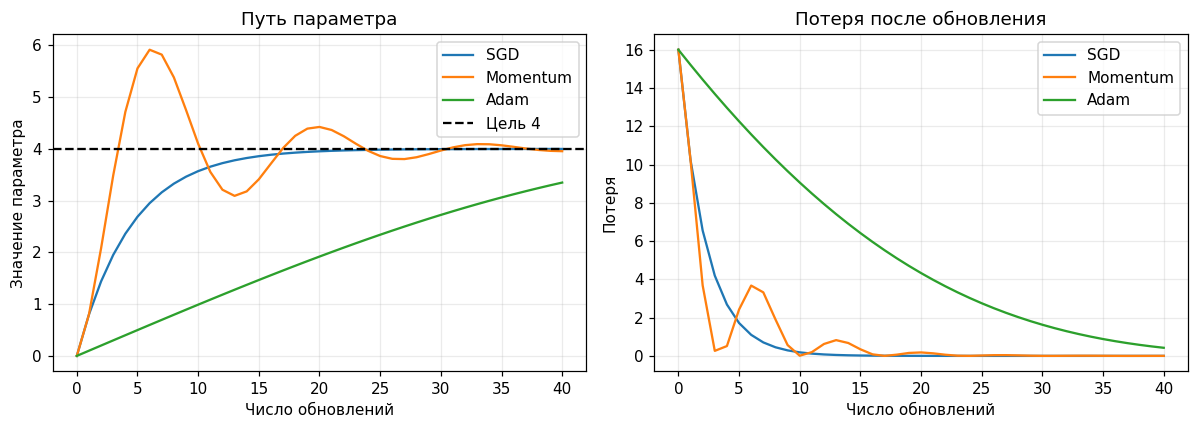

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, trace in scalar_traces.items():
    axes[0].plot(trace['Шаг'], trace['Параметр'], label=name)
    axes[1].plot(trace['Шаг'], trace['Потеря'], label=name)
axes[0].axhline(4.0, color='black', linestyle='--', label='Цель 4')
axes[0].set_title('Путь параметра')
axes[0].set_ylabel('Значение параметра')
axes[1].set_title('Потеря после обновления')
axes[1].set_ylabel('Потеря')
for ax in axes:
    ax.set_xlabel('Число обновлений')
    ax.grid(alpha=0.25)
    ax.legend()
fig.tight_layout()
plt.show()

**Разбор кода и рисунка.**

- `plt.subplots(...)` создаёт две области. Цикл по `scalar_traces.items()` берёт имя и таблицу пути. `trace['Шаг']` выбирает горизонтальную координату; `plot(...)` рисует значения параметра и потери, `label` задаёт легенду.
- `axhline(4.0, ...)` добавляет горизонтальный ориентир, `linestyle='--'` делает его пунктирным. `set_title` и `set_ylabel` задают разные подписи панелей.
- Второй цикл задаёт общий `set_xlabel`, полупрозрачную `grid` и `legend`. `tight_layout()` размещает элементы, `plt.show()` выводит результат.

Momentum в данном опыте сначала переносит параметр дальше цели, затем возвращает его с колебаниями. Потеря не обязана уменьшаться на каждом отдельном шаге. Adam с выбранным `lr` движется иначе и за 40 шагов ещё не доходит до того же результата, что простой SGD. Итоговая строка без пути скрывала бы эти различия.

### Величина шага меняет поведение того же метода

`Learning rate`, параметр `lr`, задаёт масштаб обновления. Малое значение может приводить к медленному движению; чрезмерное — к перескокам и росту потери. Оптимизатор не освобождает от выбора подходящего шага.

Свойства задачи и масштабы сигналов имеют значение. Число, которое работает в одном опыте, нельзя автоматически переносить на другую сеть. Здесь сравним только заранее заданные варианты на одном параметре, без подбора настройки для реальных данных.

Оставим простой SGD и проведём по 20 шагов с тремя значениями `lr`. Во всех строках цель 4 и исходное число 0. Сравним результат с исходной потерей 16, чтобы отличить медленное улучшение от ухудшения.

In [18]:
learning_rate_rows = []
for rate in [0.02, 0.2, 1.1]:
    rate_trace = run_scalar_training('SGD', learning_rate=rate, steps=20)
    last_row = rate_trace.iloc[-1]
    learning_rate_rows.append({
        'Learning rate': rate,
        'Исходная потеря': rate_trace.iloc[0]['Потеря'],
        'Параметр после 20 шагов': last_row['Параметр'],
        'Потеря после 20 шагов': last_row['Потеря'],
    })
display(pd.DataFrame(learning_rate_rows).set_index('Learning rate'))

,Исходная потеря,Параметр после 20 шагов,Потеря после 20 шагов
Learning rate,,,
0.02,16.0,2.2320,3.1259e+00
0.20,16.0,3.9999,2.1360e-08
1.10,16.0,-149.3505,2.3516e+04


**Разбор кода и результата.**

- Цикл перебирает три дробных числа. `run_scalar_training('SGD', ...)` создаёт каждый раз новый независимый опыт с текущим `learning_rate` и `steps=20`.
- `.iloc[-1]` выбирает конец опыта, `.iloc[0]` — исходную строку. Последующие квадратные скобки выбирают нужное поле. `.append({...})` накапливает описание каждого варианта.
- `pd.DataFrame(...)`, `.set_index(...)` и `display(...)` формируют таблицу.

Самый большой шаг в этом примере переносит параметр через цель так далеко, что потеря растёт. Это видно без изменения функции потерь или механизма `backward`: различается только масштаб обновления. Малый шаг тоже не обязательно полезнее среднего, поскольку может не успеть приблизиться к цели за заданный бюджет.

При lr=0,02 параметр дошёл примерно до 2,2320, а потеря снизилась с 16 до 3,1259. При lr=0,2 параметр приблизился к 4. При lr=1,1 он оказался около −149,3505, а потеря выросла примерно до 23 516. В таблице большое число показано компактно как `2.3516e+04`; запись `2.1360e-08` у удачного шага означает очень малую положительную потерю, около `0.00000002136`.

## 7. Целый цикл обучения небольшой сети

### Данные и одна заранее заданная конфигурация

Соберём изученные действия для задачи с двумя классами и двумя числовыми признаками. Данные искусственные, с известными ответами. Как и ранее, подготовка изучается только на обучающей части; валидационные ответы используются после обучения.

Обрабатывать будем всю обучающую часть за один шаг. **Пакет, batch**, — порция объектов, по которой вычисляется одно обновление. **Эпоха** — полный проход по обучающим объектам. В этом небольшом примере весь набор составляет один пакет, поэтому на эпоху приходится одно обновление. В схеме с несколькими пакетами одна эпоха содержала бы несколько шагов оптимизатора.

Архитектуру, Adam, `lr=0.03` и 120 эпох задаём заранее для демонстрации механизма. Подбора по валидации и независимого финального тестирования здесь нет.

Создадим 240 объектов в виде двух шумных изогнутых полос и выделим четверть для валидации. Приведём признаки к сопоставимому масштабу, затем создадим тензоры дробного типа для сети и бинарной потери. Форма целей будет «число объектов, один ответ».

In [19]:
class_values, class_labels = make_moons(n_samples=240, noise=0.18, random_state=31)
X_train, X_valid, y_train, y_valid = train_test_split(
    class_values, class_labels, test_size=0.25, stratify=class_labels, random_state=15
)
scaler = StandardScaler()
train_features = torch.tensor(scaler.fit_transform(X_train), dtype=torch.float32)
valid_features = torch.tensor(scaler.transform(X_valid), dtype=torch.float32)
train_targets = torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1)
valid_targets = torch.tensor(y_valid, dtype=torch.float32).reshape(-1, 1)

print('Обучающие признаки:', tuple(train_features.shape))
print('Обучающие цели:', tuple(train_targets.shape))
print('Валидационные признаки:', tuple(valid_features.shape))
print('Валидационные цели:', tuple(valid_targets.shape))

Обучающие признаки: (180, 2)
Обучающие цели: (180, 1)
Валидационные признаки: (60, 2)
Валидационные цели: (60, 1)


**Разбор кода и данных.**

- `make_moons(...)` создаёт признаки и метки двух полос: `n_samples` задаёт число объектов, `noise` — разброс, `random_state` — воспроизводимость. `train_test_split(...)` согласованно делит признаки и ответы. `test_size=0.25` выделяет четверть, `stratify=class_labels` учитывает доли классов, второй `random_state` закрепляет разбиение.
- `StandardScaler()` создаёт подготовку. `fit_transform(X_train)` учит её и преобразует обучение; `transform(X_valid)` применяет уже сохранённое правило к валидации. Теория подготовки данных была ранее.
- `torch.tensor(..., dtype=torch.float32)` создаёт тензоры с дробным типом, согласованным со стандартным типом параметров используемых слоёв. Для бинарной потери цели также представлены числами дробного типа 0 и 1.
- `.reshape(-1, 1)` делает один столбец целей. Здесь `-1` просит автоматически определить число строк из общего числа элементов, `1` задаёт число столбцов. Это другой контекст отрицательного числа, чем индекс последней строки `.iloc[-1]`.
- `.shape`, `tuple(...)` и `print(...)` показывают формы. Обучение содержит 180 объектов с двумя признаками и 180 целей, валидация — 60 объектов и целей.

Параметры сети должны получать признаки, а не столбец правильных ответов. Цели подаются в функцию потерь отдельно. Валидационные цели не участвовали в обучении масштабирования.

Создадим сеть с восемью скрытыми нейронами и одним бинарным логитом. Выберем Adam и прочитаем потерю исходного случайного состояния. Пока это контрольное вычисление: никаких `backward` и `step` для этой сети ещё не было.

In [20]:
torch.manual_seed(7)
main_model = nn.Sequential(nn.Linear(2, 8), nn.Tanh(), nn.Linear(8, 1))
main_optimizer = torch.optim.Adam(main_model.parameters(), lr=0.03)
with torch.no_grad():
    main_initial_loss = binary_criterion(main_model(train_features), train_targets).item()

print('Обучаемых параметров:', sum(parameter.numel() for parameter in main_model.parameters()))
print('Исходная учебная потеря:', round(main_initial_loss, 4))

Обучаемых параметров: 33
Исходная учебная потеря: 0.7823


**Разбор кода и состояния.**

- `torch.manual_seed(7)` закрепляет начальное состояние. `nn.Sequential` задаёт порядок `nn.Linear(2, 8)`, `nn.Tanh()`, `nn.Linear(8, 1)`. Выход остаётся логитом, согласованным с `binary_criterion`, то есть `BCEWithLogitsLoss`.
- `torch.optim.Adam(main_model.parameters(), lr=0.03)` создаёт один оптимизатор для всех параметров. Его будем сохранять на протяжении всех эпох, чтобы не терять историю.
- `with torch.no_grad():` ограничивает контрольный прямой проход `main_model(...)` и расчёт `binary_criterion(...)`. `.item()` извлекает число, не предназначенное для последующего `backward`.
- `.parameters()` перечисляет параметры, `.numel()` считает элементы каждого. `sum(... for ... in ...)` суммирует количества, `round(...)` округляет потерю, `print(...)` выводит сведения.

Получилось 33 обучаемых числа. Начальная потеря характеризует случайное исходное состояние на обучающих объектах, а не качество сети после обучения. Для обновления ниже вычислим новую потерю с включённым учётом градиентов.

Выполним 120 эпох полного пакета. В каждой эпохе явно очистим градиенты, получим логиты и потерю, выполним обратное распространение и шаг Adam. Для отчёта пересчитаем учебную потерю уже после обновления, без создания дополнительного обучающего графа.

In [21]:
main_model.train()
epoch_rows = [{'Эпоха': 0, 'Учебная потеря после обновления': main_initial_loss}]
for epoch in range(1, 121):
    main_optimizer.zero_grad(set_to_none=True)
    train_logits = main_model(train_features)
    train_loss = binary_criterion(train_logits, train_targets)
    train_loss.backward()
    main_optimizer.step()

    with torch.no_grad():
        updated_train_loss = binary_criterion(main_model(train_features), train_targets).item()
    epoch_rows.append({'Эпоха': epoch, 'Учебная потеря после обновления': updated_train_loss})

training_history = pd.DataFrame(epoch_rows).set_index('Эпоха')
display(training_history.loc[[0, 1, 30, 60, 90, 120]])

,Учебная потеря после обновления
Эпоха,
0,0.7823
1,0.7330
30,0.2474
60,0.2310
90,0.2241
120,0.2147


**Разбор кода и последовательности.**

- `main_model.train()` включает режим обучения у слоёв. Сам метод **не запускает цикл и не подбирает веса**: это делают последующие действия. В нашей сети только Linear и Tanh; разбор слоёв, чьё поведение зависит от режима, относится к следующей теме.
- `epoch_rows` — список словарей отчёта. Эпоха 0 обозначает исходное состояние до обновлений. `range(1, 121)` задаёт 120 эпох; цикл выполняет строки с отступом для каждой.
- `zero_grad(set_to_none=True)` очищает старые вклады. `main_model(train_features)` создаёт прямой проход с графом, `binary_criterion(...)` получает общую потерю. `train_loss.backward()` вычисляет градиенты, `main_optimizer.step()` изменяет параметры по правилу Adam.
- В блоке `torch.no_grad()` новый прямой проход и новая потеря нужны для отчёта. `.item()` переводит их результат в число. Это **не** значение старого `train_loss` до шага. `.append(...)` добавляет строку состояния после обновления.
- `pd.DataFrame(...)` создаёт историю, `.set_index('Эпоха')` задаёт номера строк. `.loc[[...]]` выбирает указанные номера **по метке индекса**, `display(...)` показывает несколько контрольных состояний.

Каждая эпоха здесь содержит один пакет и один `step`. Уменьшение учебной потери показывает подстройку под обучающие ответы, но само по себе не сообщает качество на новых объектах. Для валидации используем отдельно отложенные данные.

В сохранённой истории учебная потеря снижается примерно с 0,7823 до 0,2147 за 120 обновлений. Первая эпоха дала около 0,7330. Все эти строки рассчитаны на обучающих объектах после соответствующего изменения параметров.

Перейдём к проверке без обновления параметров. Сначала вычислим валидационную потерю по логитам, затем применим sigmoid для показа оценок класса 1. Для готовых классов используем заранее заданный порог 0,5; по этим ответам получим знакомые метрики.

In [22]:
main_model.eval()
with torch.no_grad():
    validation_logits = main_model(valid_features)
    validation_loss = binary_criterion(validation_logits, valid_targets).item()
    validation_probabilities = torch.sigmoid(validation_logits).squeeze(1).numpy()

validation_predictions = (validation_probabilities >= 0.5).astype(int)
validation_report = pd.DataFrame({
    'Факт': y_valid,
    'Оценка класса 1': validation_probabilities,
    'Предсказание': validation_predictions,
})
display(validation_report.head(8))
print('Валидационная потеря:', round(validation_loss, 4))
print('Accuracy:', round(accuracy_score(y_valid, validation_predictions), 4))
print('F1 класса 1:', round(f1_score(y_valid, validation_predictions, zero_division=0), 4))

,Факт,Оценка класса 1,Предсказание
0,1,0.9862,1
1,1,0.9948,1
2,1,0.1384,0
3,1,0.2788,0
4,0,0.2084,0
5,0,0.0298,0
6,1,0.6332,1
7,1,0.2059,0


Валидационная потеря: 0.3745
Accuracy: 0.8167
F1 класса 1: 0.8197


**Разбор кода и результата.**

- `main_model.eval()` включает режим проверки у слоёв. Он сам не отключает учёт градиентов и не повышает точность модели. `with torch.no_grad():` отдельно отключает запись нового графа для вычислений внутри блока. Эти действия имеют разные назначения.
- `main_model(valid_features)` получает логиты; `binary_criterion(...)` использует их **без sigmoid**. `.item()` извлекает валидационную потерю для отчёта.
- `torch.sigmoid(validation_logits)` превращает логиты в оценки класса 1 только для представления ответа. `.squeeze(1)` убирает второй размер, равный 1: форма `(60, 1)` становится `(60,)`. `.numpy()` передаёт числа для таблицы и метрик; они не требуют градиентов, поскольку вычислены в `no_grad`.
- Сравнение `>= 0.5` создаёт логические решения, `.astype(int)` переводит их в коды 0 и 1. `pd.DataFrame(...)` связывает их с фактами того же порядка, `head(8)` выбирает первые восемь строк, `display(...)` показывает таблицу.
- `accuracy_score(...)`, `f1_score(..., zero_division=0)`, `round(...)` и `print(...)` вычисляют и выводят знакомые показатели.

В этом блоке нет `backward` и `step`. Валидационные ответы только оценивают уже полученную сеть. Учебная потеря и валидационная потеря относятся к разным объектам; метрики классов дополнительно зависят от выбранного порога. Оценка, близкая к 1, всё равно не гарантирует правильность отдельной строки.

Получены валидационная потеря около 0,3745, accuracy около 0,8167 и F1 около 0,8197. Правильны 49 из 60 классов. Например, строка 2 в показанном фрагменте имеет факт 1, но оценку класса 1 около 0,1384 и ответ 0. Поэтому снижение учебной потери не следует интерпретировать как безошибочное решение на новых объектах.

Покажем всю историю учебной потери, включая исходное состояние. Линия описывает обучение на одних и тех же 180 объектах. Валидационная оценка выше получена отдельно после завершения заранее заданных 120 эпох.

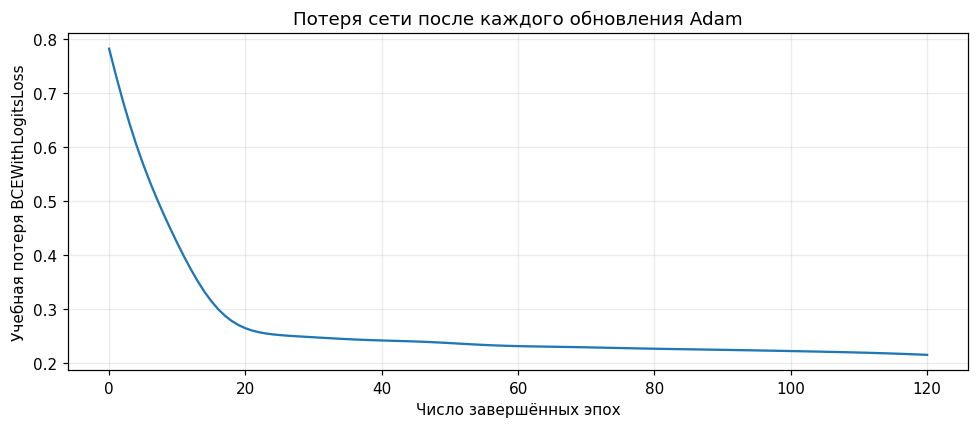

In [23]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(training_history.index, training_history['Учебная потеря после обновления'])
ax.set_xlabel('Число завершённых эпох')
ax.set_ylabel('Учебная потеря BCEWithLogitsLoss')
ax.set_title('Потеря сети после каждого обновления Adam')
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

**Разбор кода и рисунка.**

- `plt.subplots(...)` создаёт рисунок. `training_history.index` содержит номера эпох, квадратные скобки выбирают столбец потери. `plot(...)` рисует сохранённую историю без дополнительных обучающих шагов.
- `set_xlabel`, `set_ylabel`, `set_title` добавляют подписи, `grid(alpha=0.25)` — полупрозрачную сетку. `tight_layout()` размещает элементы, `plt.show()` выводит рисунок.

Снижение линии означает уменьшение выбранного учебного критерия. Оно не доказывает, что после каждого шага исправлялся каждый объект: оптимизатор получал общий сигнал пакета. Видимая линия также не устанавливает, сколько эпох было бы лучше для другой задачи или для независимого финального применения.

Получим ответы для трёх новых сочетаний сигналов и проверим, что параметры остаются прежними. Правильные классы этих строк не заданы, поэтому метрики здесь не вычисляются. Масштабирование используем сохранённое, а от сети требуется только прямое получение ответа.

In [24]:
new_signals = np.array([[0.0, 0.5], [1.0, -0.2], [1.5, 0.2]], dtype=np.float32)
new_features = torch.tensor(scaler.transform(new_signals), dtype=torch.float32)
parameters_before_inference = {
    name: parameter.detach().clone() for name, parameter in main_model.named_parameters()
}
with torch.no_grad():
    new_probabilities = torch.sigmoid(main_model(new_features)).squeeze(1).numpy()

inference_results = pd.DataFrame(new_signals, columns=['Сигнал 1', 'Сигнал 2'])
inference_results['Оценка класса 1'] = new_probabilities
inference_results['Предсказание'] = (new_probabilities >= 0.5).astype(int)
display(inference_results)
print('Все параметры сохранились:', all(
    torch.equal(parameter.detach(), parameters_before_inference[name])
    for name, parameter in main_model.named_parameters()
))

,Сигнал 1,Сигнал 2,Оценка класса 1,Предсказание
0,0.0,0.5,0.1062,0
1,1.0,-0.2,0.9801,1
2,1.5,0.2,0.8060,1


Все параметры сохранились: True


**Разбор кода и результата.**

- `np.array(..., dtype=np.float32)` создаёт три объекта с двумя признаками. `scaler.transform(...)` применяет сохранённое правило подготовки; нового обучения масштабирования нет. `torch.tensor(..., dtype=torch.float32)` согласует вход с моделью.
- Словарное включение по `.named_parameters()` сохраняет снимки параметров через `.detach().clone()`: независимые числа для сравнения, без связи с графом.
- В `torch.no_grad()` вызов `main_model(...)` получает логиты, `torch.sigmoid(...)` — оценки. `squeeze(1)` убирает единичный столбец, `numpy()` готовит вывод.
- `pd.DataFrame(...)` создаёт исходные столбцы, присваивания добавляют оценку и класс. `>= 0.5` и `.astype(int)` используют прежнее правило решения, `display(...)` показывает строки.
- `all(... for ... in ...)` проверяет каждое совпадение `torch.equal(...)` с исходным снимком, `print(...)` выводит результат. `True` означает, что все параметры остались численно прежними.

Получение оценок — прямой проход с уже обученным состоянием. Оно не требует потери, правильных ответов, `backward` или `step`. Новые данные сами по себе не дообучают модель.

## 8. Как читать цикл обучения

| Действие | Что происходит | Меняет веса? |
|---|---|---|
| Активация в прямом проходе | Преобразует текущий сигнал | Нет |
| Функция потерь | Сопоставляет выход с правильным ответом | Нет |
| `zero_grad` | Очищает сохранённые градиенты | Нет |
| `backward` | Вычисляет и накапливает чувствительности в `.grad` | Нет |
| `optimizer.step` | Применяет правило обновления и историю оптимизатора | Да, если правило и состояние дают ненулевую поправку |
| `eval` | Выбирает режим проверки у слоёв | Само по себе нет |
| `no_grad` | Временно отключает запись операций для новых градиентов | Само по себе нет |

В обучающем шаге новый прямой проход создаёт вычисления для текущих параметров. От потери запускается backpropagation, а оптимизатор отдельно изменяет состояние. Следующий шаг заново получает прогноз: старое числовое значение потери не пересчитывается автоматически.

Активации влияют и на форму ответа, и на локальную передачу обучающего сигнала. Оптимизаторы отличаются использованием текущих и накопленных градиентов. Скорость и устойчивость зависят также от величины шага и данных. Успешное уменьшение учебной потери нужно связывать с подходящей проверкой качества на отдельных объектах, а не принимать за автоматическую готовность модели к применению.

### Официальные справочные страницы

Для уточнения API: [автоматическое вычисление градиентов](https://docs.pytorch.org/docs/2.11/autograd.html), [оптимизаторы](https://docs.pytorch.org/docs/2.11/optim.html), [BCEWithLogitsLoss](https://docs.pytorch.org/docs/2.11/generated/torch.nn.BCEWithLogitsLoss.html), [CrossEntropyLoss](https://docs.pytorch.org/docs/2.11/generated/torch.nn.CrossEntropyLoss.html), [ReLU](https://docs.pytorch.org/docs/2.11/generated/torch.nn.ReLU.html), [no_grad](https://docs.pytorch.org/docs/2.11/generated/torch.no_grad.html). Ссылки ведут на документацию PyTorch 2.11; установленная версия напечатана в начале. Интернет для выполнения файла не требуется.